# Validation model comparison

Compare Logistic Regression, Random Forest, and the original XGBoost baseline retained after notebook 08. Use the seed-42 training and validation CSVs, the project’s ordered numerical features, and the binary mapping benign = 0 and attack = 1. Logistic Regression uses its fitted scaler. The tree models receive the selected features directly. An attack probability of 0.5 or greater predicts attack.

## Load the saved subsets and identify exact matches

Check the training and validation sizes and reproduce the original overlap mask across the 46 raw numeric features.

In [1]:
import sys
from pathlib import Path

import numpy as np
import sklearn
import xgboost
from IPython.display import Markdown, display
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
from xgboost import XGBClassifier

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root))

from src.batch.baseline_data import (
    ATTACK_THRESHOLD,
    TRAINING_PATH,
    VALIDATION_PATH,
    binary_targets,
    load_features,
    select_model_features,
    validation_overlap,
)
from src.batch.validate import score_predictions

training, training_labels = load_features(TRAINING_PATH)
validation, validation_labels = load_features(VALIDATION_PATH)
y_train = binary_targets(training_labels, "Training").to_numpy()
y_validation = binary_targets(validation_labels, "Validation").to_numpy()
if (len(training), len(validation)) != (100_000, 25_000):
    raise ValueError("Expected 100,000 training and 25,000 validation rows.")

shared_patterns, matches = validation_overlap(training, validation)
matched_benign, matched_attack = np.bincount(y_validation[matches], minlength=2)
if (shared_patterns, matches.sum(), matched_benign, matched_attack) != (25, 25, 2, 23):
    raise ValueError("Exact overlap differs from the baseline.")
evaluation_masks = {
    "All validation": np.ones(len(validation), dtype=bool),
    "Nonmatching only": ~matches,
}

feature_columns = select_model_features(training)
X_train = training[feature_columns]
X_validation = validation[feature_columns]
print(f"Training: {len(training):,} rows with {len(feature_columns)} selected features")
print(f"Validation: {len(validation):,} rows")
print(f"Exact matches across all 46 original features: {matches.sum()} rows "
      f"({matched_benign} benign, {matched_attack} attack) across {shared_patterns} patterns")
print(f"Nonmatching validation rows: {(~matches).sum():,}")

Training: 100,000 rows with 38 selected features
Validation: 25,000 rows
Exact matches across all 46 original features: 25 rows (2 benign, 23 attack) across 25 patterns
Nonmatching validation rows: 24,975


## Load the saved models and reproduce Random Forest

Reuse the fitted Logistic Regression pipeline and the deployed XGBoost export. Refit Random Forest on the original training subset using 100 trees, Gini splits, bootstrap sampling, square-root feature sampling, maximum depth 14, seed 42, two threads, and training-derived balanced class weights. Check the feature and class order before scoring the same validation rows for all three models.

In [2]:
import json
import pickle

from threadpoolctl import threadpool_limits
from src.batch.baseline_data import MODEL_PATH
from src.batch.predict import DEFAULT_METADATA, DEFAULT_MODEL

with MODEL_PATH.open("rb") as saved:
    logistic_artifact = pickle.load(saved)
logistic = logistic_artifact["pipeline"]
metadata = json.loads(DEFAULT_METADATA.read_text())
if logistic_artifact["feature_columns"] != feature_columns or metadata["feature_columns"] != feature_columns:
    raise ValueError("Saved feature order differs from the validation feature selection.")
if metadata["class_mapping"] != {"0": "benign", "1": "attack"} or metadata["attack_threshold"] != ATTACK_THRESHOLD:
    raise ValueError("Deployed class mapping or threshold differs from the comparison.")

boosted = XGBClassifier(device="cpu", n_jobs=2)
boosted.load_model(DEFAULT_MODEL)

classes = np.array([0, 1])
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weights = dict(zip(classes.tolist(), weights.tolist(), strict=True))

forest = RandomForestClassifier(
    n_estimators=100, criterion="gini", max_depth=14, max_features="sqrt",
    bootstrap=True, class_weight=class_weights, random_state=42, n_jobs=2,
)
models = {"Logistic Regression": logistic, "Random Forest": forest, "XGBoost": boosted}
attack_scores = {}
with threadpool_limits(limits=2):
    forest.fit(X_train, y_train)
    for name, model in models.items():
        fitted_columns = boosted.get_booster().feature_names if model is boosted else list(model.feature_names_in_)
        if fitted_columns != feature_columns or set(model.classes_) != {0, 1}:
            raise ValueError(f"{name} has an unexpected feature order or class mapping.")
        attack_index = list(model.classes_).index(1)
        attack_scores[name] = model.predict_proba(X_validation)[:, attack_index]
predictions = {
    name: (scores >= ATTACK_THRESHOLD).astype(int)
    for name, scores in attack_scores.items()
}

print(f"scikit-learn {sklearn.__version__}, XGBoost {xgboost.__version__}")
display(Markdown(
    "**Model provenance.** Logistic Regression and XGBoost used their saved fitted artifacts. "
    "Random Forest was the only refit. Its benign and attack class weights were "
    f"{weights[0]:.6f} and {weights[1]:.6f}. All three scored the same {len(X_validation):,} rows."
))

scikit-learn 1.9.1, XGBoost 3.4.1


**Model provenance.** Logistic Regression and XGBoost used their saved fitted artifacts. Random Forest was the only refit. Its benign and attack class weights were 21.195422 and 0.512080. All three scored the same 25,000 rows.

## Consolidated validation comparison

Verify the original false-alarm and missed-attack counts, then show the side-by-side matrices and metrics for the same 25,000 rows at threshold 0.5. Matrix rows are actual [benign, attack] and columns are predicted [benign, attack]. Compute ROC-AUC from the continuous attack scores. Export the numeric rates on a 0–1 scale for the dashboard.

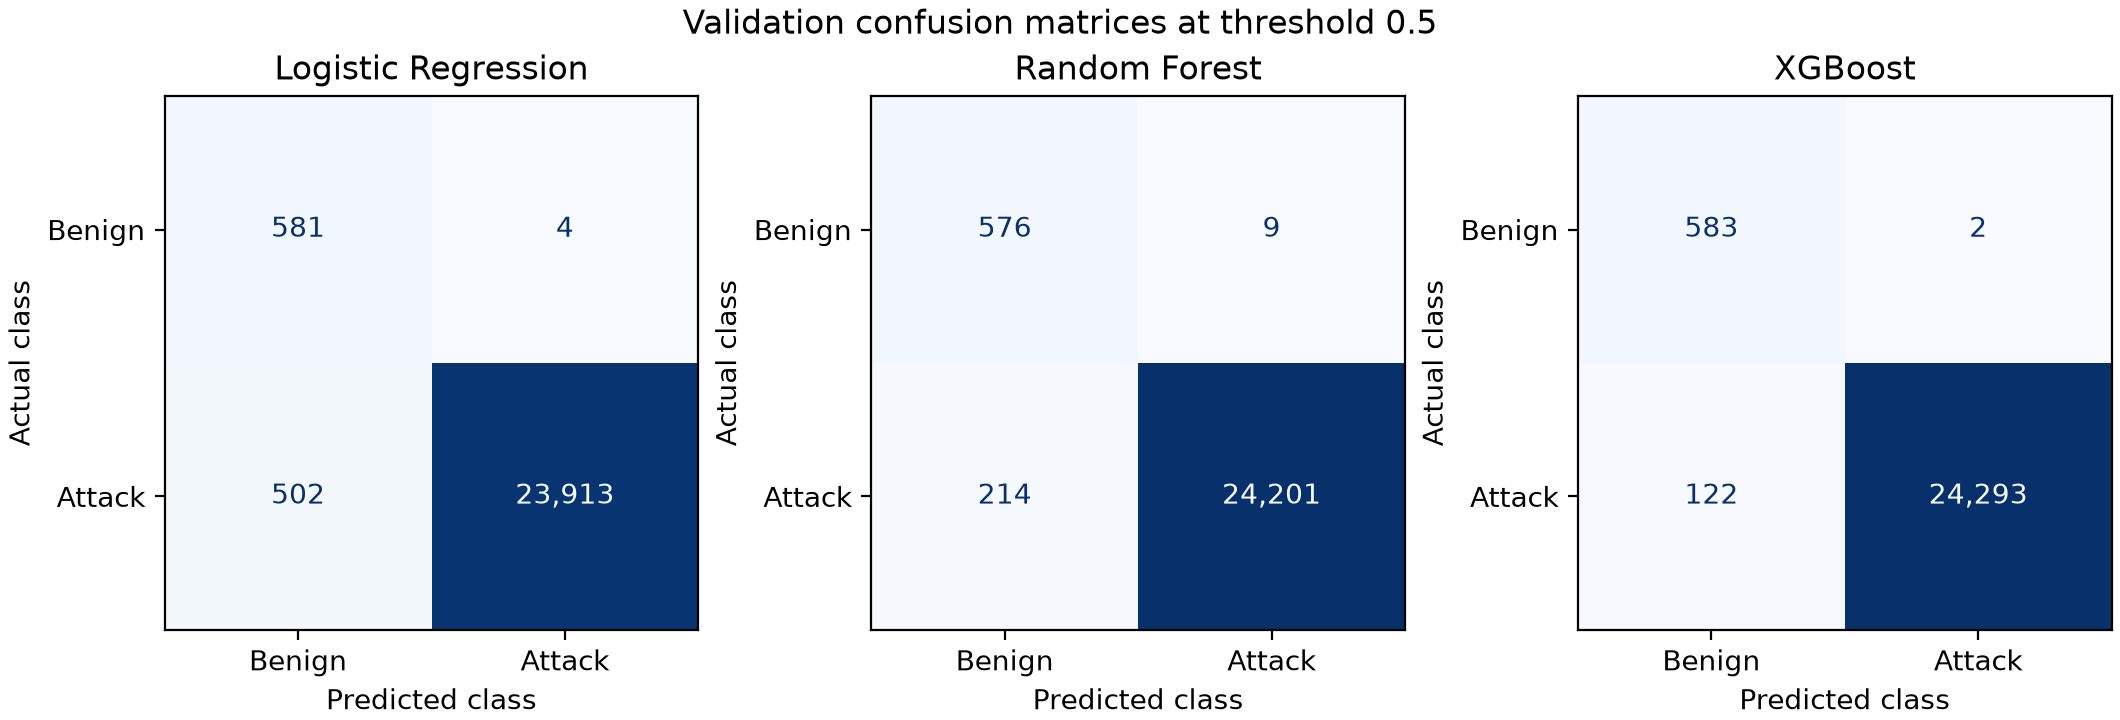

| Model | Scope | N | TN | FP | FN | TP | Accuracy | Attack precision | Attack recall | Benign precision | Benign recall | Balanced accuracy | Benign false-positive rate | ROC-AUC |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Logistic Regression | All validation | 25000 | 581 | 4 | 502 | 23913 | 97.9760% | 99.9833% | 97.9439% | 53.6473% | 99.3162% | 98.6301% | 0.6838% | 0.993571 |
| Random Forest | All validation | 25000 | 576 | 9 | 214 | 24201 | 99.1080% | 99.9628% | 99.1235% | 72.9114% | 98.4615% | 98.7925% | 1.5385% | 0.998952 |
| XGBoost | All validation | 25000 | 583 | 2 | 122 | 24293 | 99.5040% | 99.9918% | 99.5003% | 82.6950% | 99.6581% | 99.5792% | 0.3419% | 0.999509 |

**Interpretation.** At 0.5, XGBoost had the highest balanced accuracy (99.5792%), with 2 false alarms and 122 missed attacks. Of 24,295 predicted attacks, 24,293 were actual attacks, so attack precision was 99.9918%. Of 705 predicted benign rows, 122 were missed attacks, leaving 583 correct benign predictions and 82.6950% benign precision. The missed attacks account for a much larger share of predicted benign rows than false alarms account for among predicted attacks.

In [3]:
import matplotlib.pyplot as plt
from IPython.display import Image
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, roc_curve
from src.batch.validate import CLASSIFICATION_RATES, CONFUSION_COUNTS, confusion_report, format_confusion_report

def show_markdown_table(table):
    header = "| " + " | ".join(table.columns) + " |"
    divider = "| " + " | ".join(["---"] * len(table.columns)) + " |"
    rows = [
        "| " + " | ".join(map(str, row)) + " |"
        for row in table.itertuples(index=False, name=None)
    ]
    display(Markdown("\n".join([header, divider, *rows])))

metrics = confusion_report(score_predictions(y_validation, predictions, evaluation_masks))
count_columns = CONFUSION_COUNTS
extra_rates = ["Balanced accuracy", "Benign false-positive rate"]
rate_columns = [*CLASSIFICATION_RATES, *extra_rates, "Benign F1", "Attack F1"]
all_scores = metrics.xs("All validation", level="Validation")
expected_errors = {"Logistic Regression": (4, 502), "Random Forest": (9, 214), "XGBoost": (2, 122)}
for name, expected in expected_errors.items():
    observed = tuple(all_scores.loc[name, ["FP", "FN"]])
    if observed != expected:
        raise ValueError(f"{name} FP/FN mismatch. Expected {expected}, observed {observed}.")

roc_aucs = {name: roc_auc_score(y_validation, scores) for name, scores in attack_scores.items()}
comparison = all_scores[["Rows", *count_columns, *CLASSIFICATION_RATES, *extra_rates]].assign(
    **{"ROC-AUC": roc_aucs},
)
figure_dir = repo_root / "figures"
figure_dir.mkdir(exist_ok=True)
comparison.reset_index().to_json(
    figure_dir / "validation_model_comparison.json", orient="records", indent=2, double_precision=15,
)

fig, axes = plt.subplots(1, 3, figsize=(10.6, 3.6), layout="constrained")
max_count = all_scores[count_columns].to_numpy().max()
for axis, (name, row) in zip(axes, all_scores.iterrows(), strict=True):
    matrix = row[count_columns].to_numpy(dtype=int).reshape(2, 2)
    panel = ConfusionMatrixDisplay(matrix, display_labels=["Benign", "Attack"])
    panel.plot(ax=axis, cmap="Blues", colorbar=False, values_format=",d",
               im_kw={"vmin": 0, "vmax": max_count})
    axis.set(title=name, xlabel="Predicted class", ylabel="Actual class")
fig.suptitle("Validation confusion matrices at threshold 0.5")
matrix_path = figure_dir / "validation_confusion_matrices.png"
fig.savefig(matrix_path, dpi=200)
plt.close(fig)
display(Image(filename=matrix_path, width=960))

show_markdown_table(format_confusion_report(
    comparison.assign(Scope="All validation"), [*extra_rates, "ROC-AUC"],
))

xgb = comparison.loc["XGBoost"]
display(Markdown(
    f"**Interpretation.** At 0.5, XGBoost had the highest balanced accuracy "
    f"({xgb['Balanced accuracy']:.4%}), with {xgb['FP']:.0f} false alarms and {xgb['FN']:.0f} missed attacks. "
    f"Of {xgb['TP'] + xgb['FP']:,.0f} predicted attacks, {xgb['TP']:,.0f} were actual attacks, "
    f"so attack precision was {xgb['Attack precision']:.4%}. "
    f"Of {xgb['TN'] + xgb['FN']:,.0f} predicted benign rows, {xgb['FN']:,.0f} were missed attacks, "
    f"leaving {xgb['TN']:,.0f} correct benign predictions and {xgb['Benign precision']:.4%} benign precision. "
    "The missed attacks account for a much larger share of predicted benign rows than false alarms "
    "account for among predicted attacks."
))

## Validation ROC curves

Plot true-positive rate against false-positive rate from each model’s continuous attack scores. Show the full axes and magnify the crowded top-left region. Mark the deployed XGBoost cutoff using the false-positive rate and attack recall from its actual thresholded predictions.

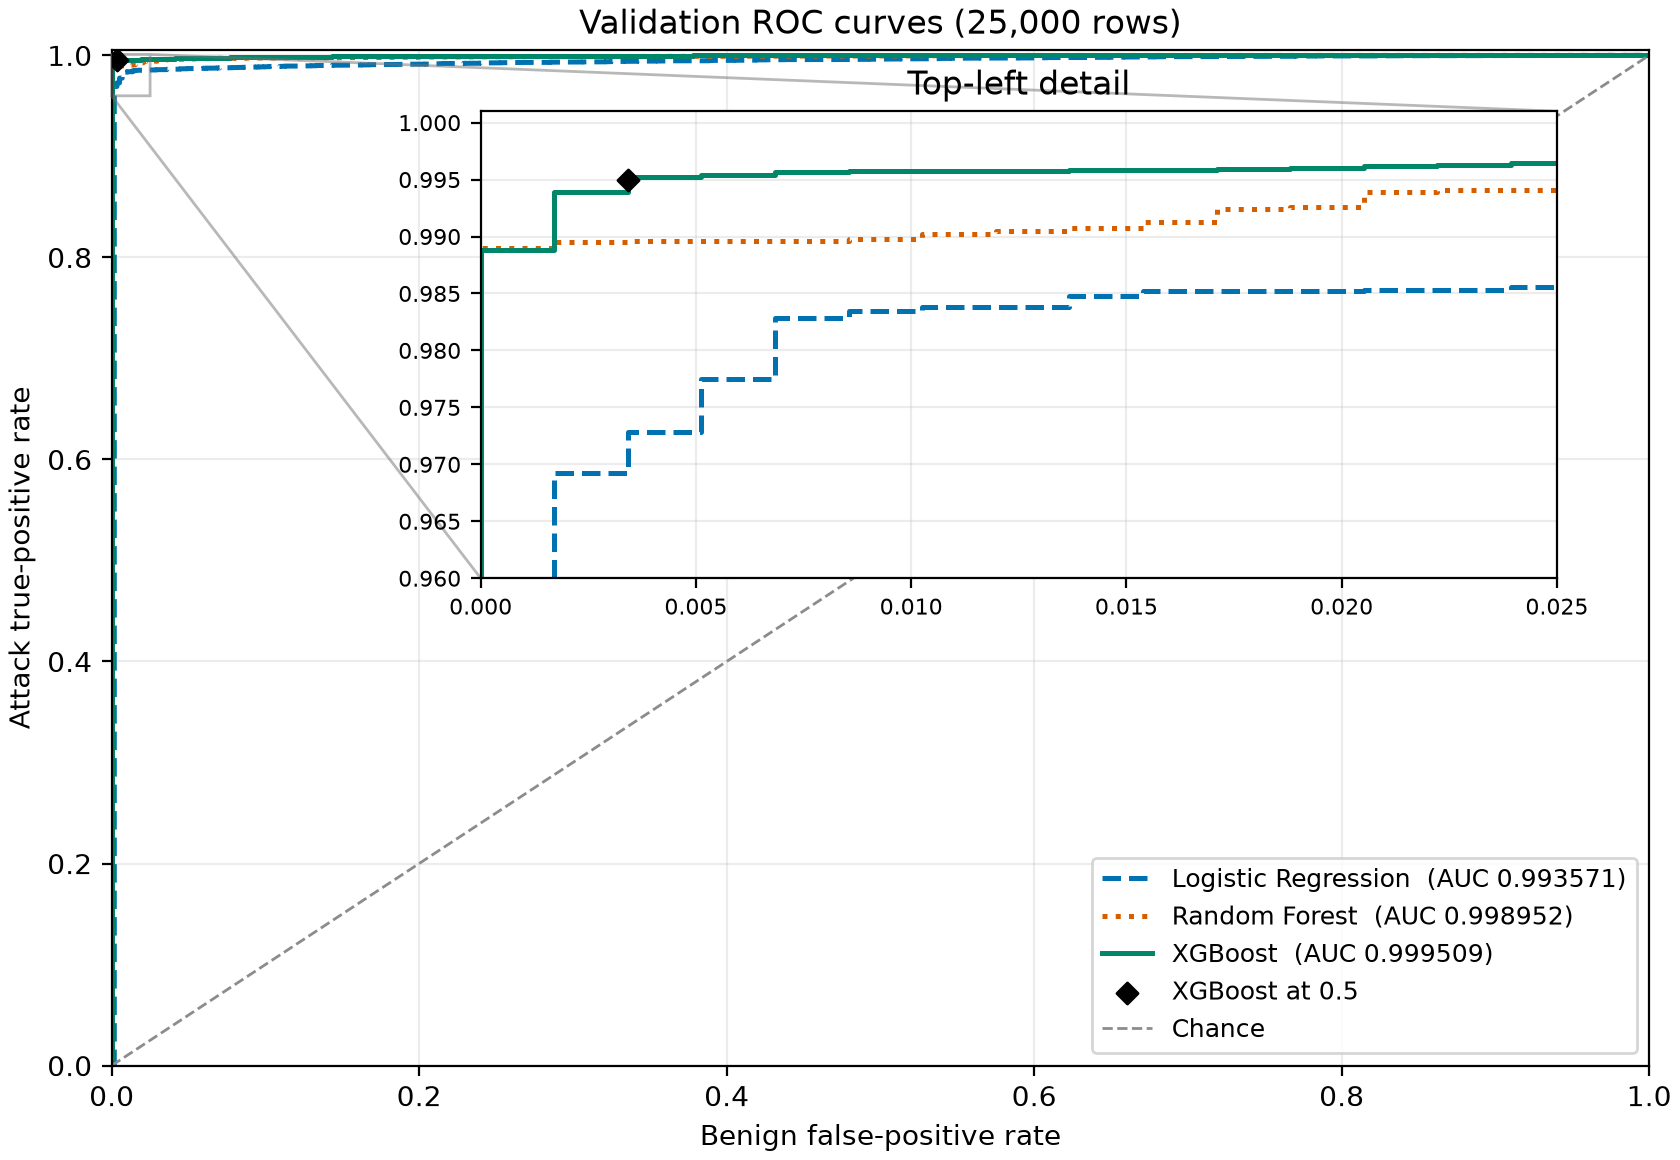

**Interpretation.** The validation AUCs were Logistic Regression 0.993571, Random Forest 0.998952, XGBoost 0.999509. XGBoost ranked attack rows above benign rows most consistently across thresholds. At the deployed 0.5 cutoff, XGBoost flagged 0.3419% of benign rows and detected 99.5003% of attack rows.

In [4]:
colors = {"Logistic Regression": "#0072B2", "Random Forest": "#D55E00", "XGBoost": "#008669"}
styles = {"Logistic Regression": "--", "Random Forest": ":", "XGBoost": "-"}
fig, ax = plt.subplots(figsize=(8.4, 5.8), layout="constrained")
zoom = ax.inset_axes([0.24, 0.48, 0.70, 0.46])
for name, scores in attack_scores.items():
    fpr, tpr, _ = roc_curve(y_validation, scores, pos_label=1)
    for axis in (ax, zoom):
        axis.plot(fpr, tpr, color=colors[name], linestyle=styles[name], linewidth=1.8,
                  label=f"{name}  (AUC {roc_aucs[name]:.6f})")

xgb_point = xgb["Benign false-positive rate"], xgb["Attack recall"]
for axis in (ax, zoom):
    axis.scatter(*xgb_point, c="black", marker="D", s=29, zorder=5, label="XGBoost at 0.5")
    axis.grid(alpha=0.23)
ax.plot([0, 1], [0, 1], color="0.55", linestyle="--", linewidth=1, label="Chance")
ax.set(xlim=(0, 1), ylim=(0, 1.005), xlabel="Benign false-positive rate",
       ylabel="Attack true-positive rate", title="Validation ROC curves (25,000 rows)")
ax.legend(loc="lower right", fontsize=9)
zoom.set(xlim=(0, 0.025), ylim=(0.96, 1.001), title="Top-left detail")
zoom.tick_params(labelsize=8)
ax.indicate_inset_zoom(zoom, edgecolor="0.45")

roc_path = figure_dir / "validation_roc.png"
fig.savefig(roc_path, dpi=200)
plt.close(fig)
display(Image(filename=roc_path, width=840))
auc_text = ", ".join(f"{name} {auc:.6f}" for name, auc in roc_aucs.items())
best_auc = max(roc_aucs, key=roc_aucs.get)
display(Markdown(
    f"**Interpretation.** The validation AUCs were {auc_text}. "
    f"{best_auc} ranked attack rows above benign rows most consistently across thresholds. "
    f"At the deployed 0.5 cutoff, XGBoost flagged {xgb_point[0]:.4%} of benign rows "
    f"and detected {xgb_point[1]:.4%} of attack rows."
))

## Table 2 — Change after excluding exact matches

Each change is nonmatching only minus all validation. Score changes use the unrounded metrics.

In [5]:
nonmatching_scores = metrics.xs("Nonmatching only", level="Validation")
change_columns = count_columns + rate_columns
changes = nonmatching_scores[change_columns] - all_scores[change_columns]
change_table = changes.copy()
for column in rate_columns:
    change_table[column] = (100 * changes[column]).map("{:+.4f} pp".format)
change_table = change_table.add_prefix("Δ ").reset_index()
show_markdown_table(change_table)

| Model | Δ TN | Δ FP | Δ FN | Δ TP | Δ Accuracy | Δ Attack precision | Δ Attack recall | Δ Benign precision | Δ Benign recall | Δ Balanced accuracy | Δ Benign false-positive rate | Δ Benign F1 | Δ Attack F1 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Logistic Regression | -2 | 0 | 0 | -23 | -0.0020 pp | -0.0000 pp | -0.0019 pp | -0.0858 pp | -0.0023 pp | -0.0021 pp | +0.0023 pp | -0.0729 pp | -0.0010 pp |
| Random Forest | -2 | 0 | 0 | -23 | -0.0009 pp | -0.0000 pp | -0.0008 pp | -0.0688 pp | -0.0053 pp | -0.0031 pp | +0.0053 pp | -0.0473 pp | -0.0004 pp |
| XGBoost | -2 | 0 | 0 | -23 | -0.0005 pp | -0.0000 pp | -0.0005 pp | -0.0492 pp | -0.0012 pp | -0.0008 pp | +0.0012 pp | -0.0299 pp | -0.0002 pp |

## Interpretation

The saved logistic regression baseline had 4 benign false alarms and 502 missed attacks on all validation rows, with 98.6301% balanced accuracy. Those error counts stayed at 4 and 502 after excluding the matches, and balanced accuracy moved to 98.6279%.

**Random Forest.** On all validation rows, it had 9 benign false alarms (more than logistic regression) and 214 missed attacks (fewer than logistic regression). Balanced accuracy was 98.7925%. Excluding the 25 matches left 9 false alarms and 214 missed attacks. Balanced accuracy changed by -0.0031 pp and the benign false-positive rate changed by +0.0053 pp.

**XGBoost.** On all validation rows, it had 2 benign false alarms (fewer than logistic regression) and 122 missed attacks (fewer than logistic regression). Balanced accuracy was 99.5792%. Excluding the 25 matches left 2 false alarms and 122 missed attacks. Balanced accuracy changed by -0.0008 pp and the benign false-positive rate changed by +0.0012 pp.